In [1]:
import math
import torch
import tiktoken
import matplotlib.pyplot as plt
from train_gpt2 import GPT, GPTConfig

enc = tiktoken.get_encoding("gpt2")
device = "cuda" if torch.cuda.is_available() else "cpu"

In [2]:
from transformers import GPT2LMHeadModel

modelo_hf = GPT2LMHeadModel.from_pretrained("gpt2")
for nome, tensor in modelo_hf.state_dict().items():
    if ".h." in nome and not nome.startswith("transformer.h.0."):
        continue  # mostra só o bloco 0, os outros 11 são idênticos em formato
    print(f"{nome:45s} {tuple(tensor.shape)}")

c:\Users\Leo\Desktop\GPT\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 148/148 [00:00<00:00, 803.48it/s]

transformer.wte.weight                        (50257, 768)
transformer.wpe.weight                        (1024, 768)
transformer.h.0.ln_1.weight                   (768,)
transformer.h.0.ln_1.bias                     (768,)
transformer.h.0.attn.c_attn.weight            (768, 2304)
transformer.h.0.attn.c_attn.bias              (2304,)
transformer.h.0.attn.c_proj.weight            (768, 768)
transformer.h.0.attn.c_proj.bias              (768,)
transformer.h.0.ln_2.weight                   (768,)
transformer.h.0.ln_2.bias                     (768,)
transformer.h.0.mlp.c_fc.weight               (768, 3072)
transformer.h.0.mlp.c_fc.bias                 (3072,)
transformer.h.0.mlp.c_proj.weight             (3072, 768)
transformer.h.0.mlp.c_proj.bias               (768,)
transformer.ln_f.weight                       (768,)
transformer.ln_f.bias                         (768,)
lm_head.weight                                (50257, 768)


In [3]:
modelo = GPT.from_pretrained("gpt2").to(device).eval()

torch.manual_seed(42)
prompt = enc.encode("Hello, I'm a language model,")
idx = torch.tensor(prompt, device=device).unsqueeze(0).repeat(5, 1)
saida = modelo.generate(idx, max_new_tokens=30, top_k=50)
for linha in saida:
    print(">", enc.decode(linha.tolist()))

Carregando pesos de gpt2...


Loading weights: 100%|██████████| 148/148 [00:00<00:00, 681.38it/s]


> Hello, I'm a language model, not a program.

So this morning I started studying for the interview in the lab. This was not a hard question, I decided to do
> Hello, I'm a language model, and one of the main things that bothers me when they create languages is how easy it becomes to create something that is difficult to understand. I find myself
> Hello, I'm a language model, and I wrote it off on the grounds that a language model would make me more fluent. But I'm not sure if that's true.


> Hello, I'm a language model, I really like languages. I like languages because like, they're good. And the way we talk about languages and, you know, we tend to
> Hello, I'm a language model, a language model I'm using for data modelling. All I did was test the results and then I wrote some equations to convert them down to numbers.


In [4]:
for temp in [0.3, 1.0, 1.8]:
    torch.manual_seed(42)
    saida = modelo.generate(idx[:1], max_new_tokens=25, temperature=temp)
    print(f"temperatura {temp}:", enc.decode(saida[0].tolist()), "\n")

temperatura 0.3: Hello, I'm a language model, not a programming language. I'm a language model. I'm a language model. I'm a language model. I'm 

temperatura 1.0: Hello, I'm a language model, not a program.

So this morning I started studying for the interview in the lab. This was not a hard question 

temperatura 1.8: Hello, I'm a language model, well, the other way around was: no idea of names, we needed some real people doing stuff like translating, but at 



In [5]:
total = sum(p.numel() for p in modelo.parameters())  # parâmetros compartilhados contam uma vez só
economia = modelo.config.vocab_size * modelo.config.n_embd
print(f"Total: {total:,}")
print(f"Sem weight tying seriam {total + economia:,} ({economia / (total + economia):.1%} a mais)")
print("wte e lm_head são o mesmo tensor?", modelo.transformer.wte.weight is modelo.lm_head.weight)

Total: 124,439,808
Sem weight tying seriam 163,037,184 (23.7% a mais)
wte e lm_head são o mesmo tensor? True


In [6]:
torch.manual_seed(0)
aleatorio = GPT(GPTConfig()).to(device).eval()
texto = open("input.txt", encoding="utf-8").read()[:5000]
tokens = torch.tensor(enc.encode(texto)[:4 * 32 + 1], device=device)
x, y = tokens[:-1].view(4, 32), tokens[1:].view(4, 32)
with torch.no_grad():
    _, loss = aleatorio(x, y)
print(f"Loss com pesos aleatórios: {loss.item():.4f} | ln(50257) = {math.log(50257):.4f}")

Loss com pesos aleatórios: 10.9931 | ln(50257) = 10.8249


In [ ]:
camada, cabeca = 5, 1
frase = "The cat sat on the mat because it was tired"
ids = enc.encode(frase)
rotulos = [enc.decode([t]) for t in ids]

modelo.transformer.h[camada].attn.use_flash = False
with torch.no_grad():
    modelo(torch.tensor(ids, device=device).unsqueeze(0))
att = modelo.transformer.h[camada].attn.last_att[0, cabeca].cpu()
modelo.transformer.h[camada].attn.use_flash = True

plt.figure(figsize=(7, 6))
plt.imshow(att, cmap="viridis")
plt.xticks(range(len(rotulos)), rotulos, rotation=60)
plt.yticks(range(len(rotulos)), rotulos)
plt.xlabel("token observado (chave)")
plt.ylabel("token que pergunta (consulta)")
plt.title(f"Atenção: camada {camada}, cabeça {cabeca}")
plt.colorbar()
plt.tight_layout()
plt.show()

TypeError: cannot unpack non-iterable int object

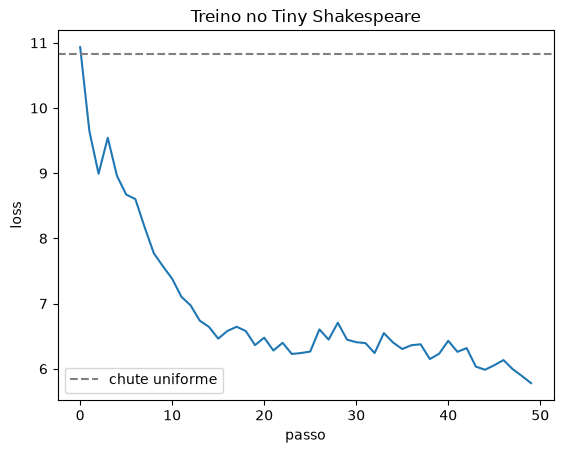

In [ ]:
losses = [float(v) for v in open("losses.txt").read().split()]
plt.plot(losses)
plt.axhline(math.log(50304), linestyle="--", color="gray", label="chute uniforme")
plt.xlabel("passo")
plt.ylabel("loss")
plt.title("Treino no Tiny Shakespeare")
plt.legend()
plt.show()